In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Read our [Gemma 3 blog](https://unsloth.ai/blog/gemma3) for what's new in Unsloth and our [Reasoning blog](https://unsloth.ai/blog/r1-reasoning) on how to train reasoning models.**

## Visit our docs for all our [model uploads](https://docs.unsloth.ai/get-started/all-our-models) and [notebooks](https://docs.unsloth.ai/get-started/unsloth-notebooks).


### Installation

In [2]:
%%capture
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth vllm
else:
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    !pip install --no-deps unsloth vllm
# Install latest Hugging Face for Gemma-3!
!pip install --no-deps git+https://github.com/huggingface/transformers@v4.49.0-Gemma-3
!pip install bitsandbytes
!pip install unsloth_zoo
!pip install msgspec
!pip install blake3
!pip install gguf
!pip install networkx==2.8.8 --force-reinstall

In [3]:
#@title Colab Extra Install { display-mode: "form" }
%%capture
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth vllm
else:
    !pip install --no-deps unsloth vllm
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    # Skip restarting message in Colab
    import sys, re, requests; modules = list(sys.modules.keys())
    for x in modules: sys.modules.pop(x) if "PIL" in x or "google" in x else None
    !pip install --no-deps bitsandbytes accelerate xformers==0.0.29.post3 peft trl triton cut_cross_entropy unsloth_zoo
    !pip install sentencepiece protobuf datasets huggingface_hub hf_transfer

    # vLLM requirements - vLLM breaks Colab due to reinstalling numpy
    f = requests.get("https://raw.githubusercontent.com/vllm-project/vllm/refs/heads/main/requirements/common.txt").content
    with open("vllm_requirements.txt", "wb") as file:
        file.write(re.sub(rb"(transformers|numpy|xformers)[^\n]{1,}\n", b"", f))
    !pip install -r vllm_requirements.txt

In [4]:
!pip uninstall -y pillow
!pip install --no-cache-dir --force-reinstall pillow==11.3.0

Found existing installation: pillow 13.0.0
Uninstalling pillow-13.0.0:
  Successfully uninstalled pillow-13.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 17.8 MB/s  0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
vllm 0.33.0 requires fastsafetensors>=0.3.3, which is not installed.
vllm 0.33.0 requires flashinfer-python==0.7.2.post1, which is not installed.
vllm 0.33.0 requires humming-kernels[cu13]==0.1.19, which is not installed.
vllm 0.33.0 requires instanttensor>=0.2.2, which is not installed.
vllm 0.33.0 requires nvidia-cudnn-frontend>=1.31.0, which is not installed.
vllm 0.33.0 requires nvidia-cutlass-dsl[cu13]==4.8.0, which is not installed.
vllm 0.33.0 requires PyNvVideoCodec==2.0.4, which is not installed.
vllm 0.33.0 requires quack-kernels==0.6.5, which is not installed.
vllm 0.33.0 requires tilelang==0.1.12, which is not installed

### Unsloth

`FastModel` supports loading nearly any model now! This includes Vision and Text models!

In [1]:
from unsloth import FastModel
import torch

fourbit_models = [
    # 4bit dynamic quants for superior accuracy and low memory use
    "unsloth/gemma-3-1b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-4b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-12b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-27b-it-unsloth-bnb-4bit",

    # Other popular models!
    "unsloth/Llama-3.1-8B",
    "unsloth/Llama-3.2-3B",
    "unsloth/Llama-3.3-70B",
    "unsloth/mistral-7b-instruct-v0.3",
    "unsloth/Phi-4",
] # More models at https://huggingface.co/unsloth

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-3-4b-it",
    max_seq_length = 2048, # Choose any for long context!
    load_in_4bit = True,  # 4 bit quantization to reduce memory
    load_in_8bit = False, # [NEW!] A bit more accurate, uses 2x memory
    full_finetuning = False, # [NEW!] We have full finetuning now!
    # token = "hf_...", # use one if using gated models
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1116 01:33:55.337000 13552 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1116 01:33:55.414000 13552 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
/usr/local/lib/python3.13/dist-packages/transformers/configuration_utils.py:726: FutureWarning: `rope_scaling` is deprecated and will be removed in a future version. Set `rope_parameters` instead, with `rope_type` and `rope_theta` included.
  warnings.warn(
W1116 01:33:57.871000 13552 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1116 01:33:57.875000 13552 torch/_library/opaque_object.py:

🦥 Unsloth Zoo will now patch everything to make training faster!


/usr/local/lib/python3.13/dist-packages/unsloth_zoo/temporary_patches/gemma.py:279: FutureWarning: `Gemma3ProcessorKwargs` is deprecated and will be removed in version 5.29.0. Use `ProcessingKwargs` instead.
  from transformers.models.gemma3.processing_gemma3 import Gemma3ProcessorKwargs


==((====))==  Unsloth 2026.11.4: Fast Gemma3 patching. Transformers: 5.23.0. vLLM: 0.33.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


We now add LoRA adapters so we only need to update a small amount of parameters!

In [2]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False, # Turn off for just text!
    finetune_language_layers   = True,  # Should leave on!
    finetune_attention_modules = True,  # Attention good for GRPO
    finetune_mlp_modules       = True,  # SHould leave on always!

    r = 8,           # Larger = higher accuracy, but might overfit
    lora_alpha = 8,  # Recommended alpha == r at least
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
)

<a name="Data"></a>
### Data Prep
We now use the `Gemma-3` format for conversation style finetunes. We use [Maxime Labonne's FineTome-100k](https://huggingface.co/datasets/mlabonne/FineTome-100k) dataset in ShareGPT style. Gemma-3 renders multi turn conversations like below:

```
<bos><start_of_turn>user
Hello!<end_of_turn>
<start_of_turn>model
Hey there!<end_of_turn>
```

We use our `get_chat_template` function to get the correct chat template. We support `zephyr, chatml, mistral, llama, alpaca, vicuna, vicuna_old, phi3, llama3, phi4, qwen2.5, gemma3` and more.

In [3]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

In [6]:
from datasets import load_dataset

dataset = load_dataset(
    'csv',
    data_files="/content/dataasilida_cleaned.csv"
)


# Access the 'train' split and display the first few rows using pandas
print(dataset['train'].to_pandas().head())

Generating train split: 0 examples [00:00, ? examples/s]

                                        input,output  \
0  ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ...   
1  លោកអ្នកទទួលបានអត្ថប្រយោជន៍ពីការប្រើប្រាស់ ប័ណ្...   
2  លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដ...   
3  លោកអ្នកអាចដកប្រាក់បានរហូតដល់ ១០០០០ដុល្លារអាមេរ...   
4  ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភា...   

                                   __index_level_0__  
0      តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី  
1  តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ផ្តល់នូ...  
2  តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេ...  
3  តើខ្ញុំអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដក...  
4  តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពល...  


In [7]:
# Rename columns safely
if "input,output" in dataset["train"].column_names:
    dataset = dataset.rename_column("input,output", "input")
if "__index_level_0__" in dataset["train"].column_names:
    dataset = dataset.rename_column("__index_level_0__", "output")
print(dataset['train'].to_pandas().head())

                                               input  \
0  ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ...   
1  លោកអ្នកទទួលបានអត្ថប្រយោជន៍ពីការប្រើប្រាស់ ប័ណ្...   
2  លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដ...   
3  លោកអ្នកអាចដកប្រាក់បានរហូតដល់ ១០០០០ដុល្លារអាមេរ...   
4  ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភា...   

                                              output  
0      តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី  
1  តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ផ្តល់នូ...  
2  តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេ...  
3  តើខ្ញុំអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដក...  
4  តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពល...  


In [8]:
import pandas as pd

# Convert Hugging Face dataset split to a pandas DataFrame for analysis
df = dataset['train'].to_pandas()

print("1. Checking for True Missing Values (NaN/None)")
print(df.isnull().sum())
print("\n")

print("2. Checking for Empty Spaces (Blank/Whitespace Strings)")
# Check if cells are empty string or contain only whitespace
empty_spaces_input = df['input'].apply(lambda x: str(x).strip() == '').sum() if 'input' in df.columns else 0
empty_spaces_output = df['output'].apply(lambda x: str(x).strip() == '').sum() if 'output' in df.columns else 0

print(f"Empty spaces in 'input': {empty_spaces_input}")
print(f"Empty spaces in 'output': {empty_spaces_output}")

print("\n" )
print("3. Checking for Duplicate Rows")
duplicate_count = df.duplicated().sum()
print(f"Total fully duplicate rows: {duplicate_count}")


1. Checking for True Missing Values (NaN/None)
input     7
output    0
dtype: int64


2. Checking for Empty Spaces (Blank/Whitespace Strings)
Empty spaces in 'input': 0
Empty spaces in 'output': 0


3. Checking for Duplicate Rows
Total fully duplicate rows: 1


In [9]:
# 1. Convert back to pandas to easily drop duplicates and NaNs
df_cleaned = dataset['train'].to_pandas()

# 2. Drop any rows where 'input' or 'output' is missing (NaN)
df_cleaned = df_cleaned.dropna(subset=['input', 'output'])

# 3. Drop duplicate rows
df_cleaned = df_cleaned.drop_duplicates()

# 4. Convert the cleaned pandas DataFrame back into a Hugging Face Dataset split
from datasets import Dataset, DatasetDict
cleaned_dataset = Dataset.from_pandas(df_cleaned, preserve_index=False)

# Overwrite our dataset dictionary's train split with the cleaned dataset
dataset['train'] = cleaned_dataset

print("Dataset Cleaned Successfully")
print(f"New dataset row count: {len(dataset['train'])}")
print(dataset['train'].to_pandas().isnull().sum())

print("\nSample")
print(dataset['train'].to_pandas().head())

Dataset Cleaned Successfully
New dataset row count: 513
input     0
output    0
dtype: int64

Sample
                                               input  \
0  ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ...   
1  លោកអ្នកទទួលបានអត្ថប្រយោជន៍ពីការប្រើប្រាស់ ប័ណ្...   
2  លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដ...   
3  លោកអ្នកអាចដកប្រាក់បានរហូតដល់ ១០០០០ដុល្លារអាមេរ...   
4  ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភា...   

                                              output  
0      តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី  
1  តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ផ្តល់នូ...  
2  តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេ...  
3  តើខ្ញុំអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដក...  
4  តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពល...  


### Split the Dataset into Train and Validation Sets
Splitting the dataset ensures we can evaluate how well our model learns. We will use Hugging Face's native `.train_test_split` method to split 80% for training and 20% for validation.

In [10]:
# Perform an 80/20 train/test split on our cleaned Hugging Face dataset
splitted_dataset = dataset['train'].train_test_split(test_size=0.2, seed=3407)

# This gives us a DatasetDict with 'train' and 'test' keys
dataset = splitted_dataset
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 410
    })
    test: Dataset({
        features: ['input', 'output'],
        num_rows: 103
    })
})


In [11]:
df = dataset['train'].to_pandas()
display(df.head(10))
dataset['train']['input'][0]

,input,output
0,ធនាគារ អេស៊ីលីដា ភីអិលស៊ី ចេញលិខិតអះអាងលើគណនី ...,តើអតិថិជនអាចស្នើសុំឲ្យធនាគារចេញលិខិតអះអាងលើគណន...
1,ពិតប្រាកដ​ណាស់​ លោកអ្នក​អាច​ប្រើប្រាស់​បាន​ភ្ល...,តើ​ខ្ញុំអាច​ប្រើប្រាស់ អ៉ីអនកាត បាន​ភ្លាមៗ​បន្...
2,អតិថិជនត្រូវមានគណនីប្រភព (គណនីធនាគារ) ជាប្រាក់...,តើត្រូវមានលក្ខខណ្ឌតម្រូវអ្វីខ្លះ សម្រាប់ការស្ន...
3,– អាយុពី១៨ ដល់ ៦៥ ឆ្នាំ​ \n – មាន​អត្តសញ្ញាណ​ប...,តើមាន​លក្ខខណ្ឌ​តម្រូវ អ្វីខ្លះ​ដើម្បី​ធ្វើការ​...
4,\nមានគណនីជាមួយធនាគារ អេស៊ីលីដា ភីអិលស៊ី \n ជាក...,តើមានតម្រូវការអ្វីខ្លះពីអតិថិជន ដើម្បីចេញលិខិត...
5,អតិថិជនត្រូវដាក់ប្រាក់តម្កល់ដំបូង បើពុំនោះទេ ល...,តើការបើកគណនីពីក្រៅប្រទេស តម្រូវឲ្យដាក់ប្រាក់តម...
6,អតិថិជនដែលជាពាណិជ្ជករត្រូវអញ្ជើញមកកាន់សាខារបស់...,តើធ្វើដូចម្តេចទើបអាចដាក់ពាក្យស្នើសុំប្រើប្រាស់...
7,\nការចំណាយលើកម្រៃសេវាសមរម្យ។ \n រក្សាការសម្ងាត...,តើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីស...
8,លោក-អ្នក​អាច​ដកប្រាក់​បាន​រហូត​ដល់ ១០០០០​ដុល្ល...,តើ​ខ្ញុំ​អាច​ប្រើ​ប័ណ្ណឥណពន្ធ​យូភីអាយ​អេស៊ីលីដ...
9,ចលនវត្ថុជួល (Leased Asset) \n ចលនវត្ថុដែលទិញសម...,តើប្រភេទចលនវត្ថុបែបណា ដែលអាចជួលបាន


'ធនាគារ អេស៊ីលីដា ភីអិលស៊ី ចេញលិខិតអះអាងលើគណនី និងព័ត៌មានអតិថិជន ទៅតាមការស្នើសុំជាលាយលក្ខណ៍អក្សររបស់អតិថិជន។ ធនាគារអាចចេញលិខិតប្រភេទនេះ បានតាមតម្រូវការរបស់អតិថិជន ឲ្យតែព័ត៌មានទាំងនោះជាព័ត៌មានពិតប្រាកដ និងជាក់ស្តែងនៃប្រតិបត្តិការផលិតផល-សេវាកម្ម ដែលអតិថិជនបាននិងកំពុងប្រើប្រាស់ជាមួយធនាគារ គិតត្រឹមកាលបរិច្ឆេទណាមួយជាក់លាក់នៅក្នុងអតីតកាល ឬបច្ចុប្បន្នកាល។'

In [12]:
def formatting_prompts_func(examples):
    instructions = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, output in zip(instructions, outputs):
        # Strictly coerce elements to string and handle potential None values safely
        instruction_str = str(instruction) if instruction is not None else ""
        output_str = str(output) if output is not None else ""

        messages = [
            {
                "role": "user", "content": instruction_str.strip()
            },
            {
                "role": "assistant", "content": output_str.strip()
            }
        ]
        text = tokenizer.apply_chat_template(messages, add_generation_prompt=False, tokenize=False)
        texts.append(text)
    return {"text": texts}

### Map the Formatting Function to both Splits
Now we apply our formatting prompts to both our `'train'` and `'test'` splits.

In [13]:
# 1. Explicitly rename columns in both train and test splits to 'input' and 'output'
for split in dataset.keys():
    current_cols = dataset[split].column_names
    # Rename raw input column
    if "input,output" in current_cols:
        dataset[split] = dataset[split].rename_column("input,output", "input")
    # Rename raw index column to output
    if "__index_level_0__" in current_cols:
        dataset[split] = dataset[split].rename_column("__index_level_0__", "output")

# 2. Map formatting prompts across both splits
dataset = dataset.map(
    formatting_prompts_func,
    batched=True
)

print(dataset)

Map:   0%|          | 0/410 [00:00<?, ? examples/s]

Map:   0%|          | 0/103 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 410
    })
    test: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 103
    })
})


In [14]:
dataset['train']['text'][0]

'<bos><start_of_turn>user\nធនាគារ អេស៊ីលីដា ភីអិលស៊ី ចេញលិខិតអះអាងលើគណនី និងព័ត៌មានអតិថិជន ទៅតាមការស្នើសុំជាលាយលក្ខណ៍អក្សររបស់អតិថិជន។ ធនាគារអាចចេញលិខិតប្រភេទនេះ បានតាមតម្រូវការរបស់អតិថិជន ឲ្យតែព័ត៌មានទាំងនោះជាព័ត៌មានពិតប្រាកដ និងជាក់ស្តែងនៃប្រតិបត្តិការផលិតផល-សេវាកម្ម ដែលអតិថិជនបាននិងកំពុងប្រើប្រាស់ជាមួយធនាគារ គិតត្រឹមកាលបរិច្ឆេទណាមួយជាក់លាក់នៅក្នុងអតីតកាល ឬបច្ចុប្បន្នកាល។<end_of_turn>\n<start_of_turn>model\nតើអតិថិជនអាចស្នើសុំឲ្យធនាគារចេញលិខិតអះអាងលើគណនី និងព័ត៌មានអតិថិជន លើព័ត៌មានអ្វីខ្លះ<end_of_turn>\n'

Let's see how row 100 looks like!

In [15]:
dataset['train']['input'][0]

'ធនាគារ អេស៊ីលីដា ភីអិលស៊ី ចេញលិខិតអះអាងលើគណនី និងព័ត៌មានអតិថិជន ទៅតាមការស្នើសុំជាលាយលក្ខណ៍អក្សររបស់អតិថិជន។ ធនាគារអាចចេញលិខិតប្រភេទនេះ បានតាមតម្រូវការរបស់អតិថិជន ឲ្យតែព័ត៌មានទាំងនោះជាព័ត៌មានពិតប្រាកដ និងជាក់ស្តែងនៃប្រតិបត្តិការផលិតផល-សេវាកម្ម ដែលអតិថិជនបាននិងកំពុងប្រើប្រាស់ជាមួយធនាគារ គិតត្រឹមកាលបរិច្ឆេទណាមួយជាក់លាក់នៅក្នុងអតីតកាល ឬបច្ចុប្បន្នកាល។'

Let's see how the chat template did! Notice `Gemma-3` default adds a `<bos>`!

In [16]:
dataset['train']['output'][00]

'តើអតិថិជនអាចស្នើសុំឲ្យធនាគារចេញលិខិតអះអាងលើគណនី និងព័ត៌មានអតិថិជន លើព័ត៌មានអ្វីខ្លះ'

<a name="Train"></a>
### Train the model
Now let's use Huggingface TRL's `SFTTrainer`! More docs here: [TRL SFT docs](https://huggingface.co/docs/trl/sft_trainer). We do 60 steps to speed things up, but you can set `num_train_epochs=1` for a full run, and turn off `max_steps=None`.

In [17]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset['train'],
    dataset_text_field = "text",
    #max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False, # Can make training 5x faster for short sequences.
    args = TrainingArguments(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        max_steps = 60,
        learning_rate = 2e-4,
        fp16 = not is_bfloat16_supported(),
        bf16 = is_bfloat16_supported(),
        logging_steps = 1,
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "none", # Use this for WandB etc
    ),
)

Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/410 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


We also use Unsloth's `train_on_completions` method to only train on the assistant outputs and ignore the loss on the user's inputs. This helps increase accuracy of finetunes!

In [18]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<start_of_turn>user\n",
    response_part = "<start_of_turn>model\n",
)

Map:   0%|          | 0/410 [00:00<?, ? examples/s]

Let's verify masking the instruction part is done! Let's print the 100th row again:

In [19]:
tokenizer.decode(trainer.train_dataset[100]["input_ids"])

'<bos><start_of_turn>user\nទំហឥណទាន \\n ទំហំឥណទានអតិបរមា ១៥០០០០ដុល្លារអាមេរិក ឬសមមូលជាប្រាក់រៀល ។ \\n រយៈពេលខ្ចីអតិបរមា ៧២ខែ (ចិតសិបពីរខែ) ។<end_of_turn>\n<start_of_turn>model\nតើទំហំឥណទាន និងរយៈពេលខ្ចីអាចបានប៉ុន្មានដែរ<end_of_turn>\n'

Now let's print the masked out example - you should see only the answer is present:

In [ ]:
tokenizer.decode([tokenizer.pad_token_id if x == -100 else x for x in trainer.train_dataset[100]["labels"]]).replace(tokenizer.pad_token, " ")

In [ ]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

In [ ]:
trainer_stats = trainer.train()

In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

<a name="Inference"></a>
### Inference
Let's run the model via Unsloth native inference! According to the `Gemma-3` team, the recommended settings for inference are `temperature = 1.0, top_p = 0.95, top_k = 64`

In [ ]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)
messages = [{
    "role": "user",
    "content": [{
        "type" : "text",
        "text" : "ទៅមុខ១០មហើយបត់ឆ្វេង",
    }]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)
outputs = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
)
tokenizer.batch_decode(outputs)

 You can also use a `TextStreamer` for continuous inference - so you can see the generation token by token, instead of waiting the whole time!

In [ ]:
messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "ទៅមុខ១០ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, either use Huggingface's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters, and not the full model. To save to 16bit or GGUF, scroll down!

In [ ]:
model.save_pretrained("gemma-3")  # Local saving
tokenizer.save_pretrained("gemma-3")
# model.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving
# tokenizer.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving

Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [ ]:
if False:
    from unsloth import FastModel
    model, tokenizer = FastModel.from_pretrained(
        model_name = "lora_model", # YOUR MODEL YOU USED FOR TRAINING
        max_seq_length = 2048,
        load_in_4bit = True,
    )

messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "បន្តទៅក្រោយ៩ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

In [20]:
def ask_gemma(question):
    messages = [{
        "role": "user",
        "content": [{"type": "text", "text": question}]
    }]
    text = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
    )
    inputs = tokenizer([text], return_tensors="pt").to("cuda")
    outputs = model.generate(
        **inputs,
        max_new_tokens=128,
        temperature=1.0,
        top_p=0.95,
        top_k=64
    )
    # Decode output while skipping the prompt tokens
    prompt_length = inputs["input_ids"].shape[1]
    response = tokenizer.decode(outputs[0][prompt_length:], skip_special_tokens=True)
    return response.strip()

test_questions = [
    "តើប័ណ្ណឥណពន្ធគឺជាអ្វី?",
    "តើធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មអ្វីខ្លះ?",
    "តើម៉ាស៊ីន ATM ប្រើប្រាស់សម្រាប់អ្វី?",
    "តើ​ធ្វើ​ដូចម្តេច​ទើប​ខ្ញុំ​អាច ស្នើសុំ​ប័ណ្ណឥណពន្ធ​យូភីអាយអេស៊ីលីដា ធម្មតា បាន?"
]

for i, question in enumerate(test_questions, 1):
    print(f"\n{'='*50}")
    print(f"Question {i}: {question}")
    print(f"Answer: {ask_gemma(question)}")


Question 1: តើប័ណ្ណឥណពន្ធគឺជាអ្វី?
Answer: ប័ណ្ណឥណពន្ធ (Credit Card) គឺជាឥតិវត្ថុ ដែលអនុញ្ញាតឱ្យអ្នកប្រើប្រាស់អាចទិញឥណសំលេង (ซื้อสินค้า ឬសេវា) ពីក្រុមហ៊ុនค้า ដោយមិនចាំបាច់មានលុយនៅពេលនោះទេ។ អ្នកនឹងត្រូវបង់ថ្លៃលើឥណសំលេងនោះ នៅពេលក្រោយតាមរយៈការបង់ថ្លៃរាល់ខែ ឬនៅពេលដែលទិញឥណសំលេង។

**ធាតុផ្សំសំខាន់ៗនៃប័ណ្ណឥណពន្ធ:**

*   **បន្ទុក

Question 2: តើធនាគារ អេស៊ីលីដា ផ្តល់សេវាកម្មអ្វីខ្លះ?
Answer: ធនាគារ អេស៊ីលីដា (Acleda Bank) ផ្តល់សេវាកម្មជាច្រើនប្រភេទ សម្រាប់អ្នកដែលប្រើប្រាស់ធនាគារ។ ខាងក្រោមនេះជាបញ្ជីសេវាកម្មសំខាន់ៗដែលធនាគារនេះផ្តល់ជូន:

**1. សេវាកម្មធនាគាររូបិយប័ណ្ចប់ (Deposit Services):**

*   **គណនារូបិយប័ណ្ចប់:** ធនាគារមានប្រភេទគណនារូបិយប័ណ្ចប់ខុសៗគ្នា សម្រាប់

Question 3: តើម៉ាស៊ីន ATM ប្រើប្រាស់សម្រាប់អ្វី?
Answer: ម៉ាស៊ីន ATM (Automated Teller Machine) គឺប្រើប្រាស់សម្រាប់ជាច្រើនមុខងារសំខាន់ៗ ដូចខាងក្រោម នេះ៖

*   **ធ្វើ withdrawals (ទាញលុយ):** នេះជាមុខងារដែលគេស្គាល់ជាងគេបំផុត គឺអាចទាញលុយពីគណឌីតរបស់អ្នកបាន
*   **ដាក់លុយ (deposits):** ក្នុងករណីខ្លះ ម៉ាស៊ីន ATM អាចអនុញ្ញ Permits ឱ្យអ្នកដាក់ល

### Complete SFT Training Pipeline with Validation Tracking

We set up our training parameters using `SFTConfig`, wrap our model with the Unsloth PEFT adapters, define our trainer using our `'train'` split for training and `'test'` split as our validation dataset, plot the performance, and then perform inference.

In [24]:
from trl import SFTTrainer, SFTConfig
import torch

training_args = SFTConfig(
    output_dir="gemma3-khmer-results",
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    num_train_epochs=3,
    learning_rate=2e-4,
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    fp16=not torch.cuda.is_bf16_supported(),
    bf16=torch.cuda.is_bf16_supported(),
    report_to="none",
    seed=42,
)

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


In [38]:
from unsloth import FastModel
from peft import PeftModel

# Check if LoRA adapters are already attached to avoid the RuntimeError
if isinstance(model, PeftModel):
    print("LoRA adapters are already attached to this model. Skipping initialization to prevent duplicates!")
else:
    model = FastModel.get_peft_model(
        model,
        # Fine-tune language layers
        finetune_vision_layers=False,
        finetune_language_layers=True,
        finetune_attention_modules=True,
        finetune_mlp_modules=True,
        # LoRA configuration
        r=8,
        lora_alpha=8,
        lora_dropout=0,
        bias="none",
        # Training optimization
        use_gradient_checkpointing="unsloth",
        random_state=3407,
        max_seq_length=2048,
    )
    print("LoRA adapters attached successfully!")

LoRA adapters are already attached to this model. Skipping initialization to prevent duplicates!


In [39]:
from trl import SFTTrainer
import os

# Temporarily disable Unsloth's precompiled cache compiler to avoid the 'is_fsdp2' Accelerate bug
os.environ["UNSLOTH_COMPILE_CACHE"] = "0"

trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    args=training_args,
)

print("SFTTrainer created successfully (compiled cache disabled)!")

Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: not enough free memory for dataset tokenization workers (~1GB each); tokenizing in-process.
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"]:   0%|          | 0/410 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"]:   0%|          | 0/103 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free enabled, enabling faster training.
SFTTrainer created successfully (compiled cache disabled)!


In [40]:
# Run training normally since the compiled cache was disabled via environment variables
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 410 | Num Epochs = 3 | Total steps = 156
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss
1,0.989571,1.217744
2,0.932012,1.175236
3,0.648727,1.171175


In [41]:
import pandas as pd

history = trainer.state.log_history
loss_df = pd.DataFrame(history)

display(
    loss_df[
        [c for c in ["step", "epoch", "loss", "eval_loss"]
         if c in loss_df.columns]
    ]
)

,step,epoch,loss,eval_loss
0,5,0.097561,0.995236,NaN
1,10,0.195122,1.037638,NaN
2,15,0.292683,1.063133,NaN
3,20,0.390244,1.212822,NaN
4,25,0.487805,1.064521,NaN
5,30,0.585366,1.116372,NaN
6,35,0.682927,1.072194,NaN
7,40,0.780488,1.048643,NaN
8,45,0.878049,0.989559,NaN
9,50,0.975610,0.989571,NaN


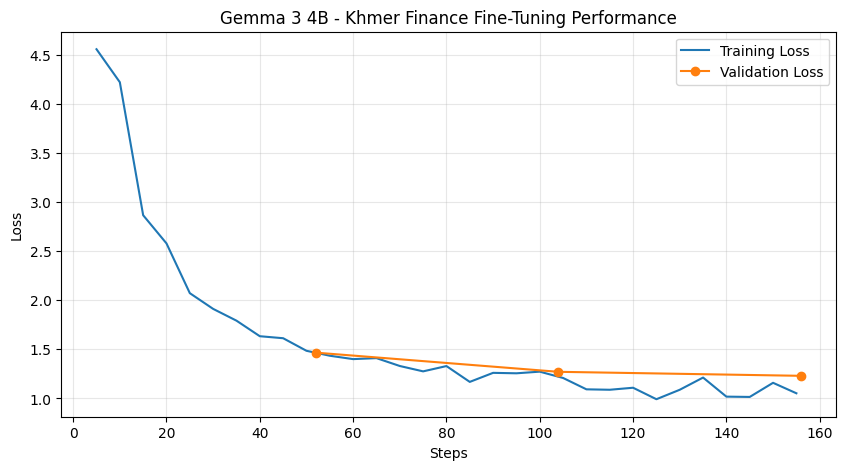

In [36]:
import matplotlib.pyplot as plt
import pandas as pd

history_df = pd.DataFrame(trainer.state.log_history)

plt.figure(figsize=(10, 5))

# Safely extract and plot training loss if it exists
if "loss" in history_df.columns:
    train_df = history_df.dropna(subset=["loss"])
    plt.plot(train_df["step"], train_df["loss"], label="Training Loss")

# Safely extract and plot validation loss if it exists
if "eval_loss" in history_df.columns:
    valid_df = history_df.dropna(subset=["eval_loss"])
    plt.plot(valid_df["step"], valid_df["eval_loss"], marker="o", label="Validation Loss")

plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Gemma 3 4B - Khmer Finance Fine-Tuning Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [42]:
model.save_pretrained("gemma3-khmer-lora")
tokenizer.save_pretrained("gemma3-khmer-lora")
print("LoRA adapter saved!")

LoRA adapter saved!


In [43]:
from unsloth import FastModel

FastModel.for_inference(model)

def ask_gemma(question, max_new_tokens=256):
    messages = [
        {
            "role": "user",
            "content": question
        }
    ]
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id
        )
    answer = tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True
    )
    return answer.strip()

questions = [
    "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី?",
    "តើអតិថិជនត្រូវមានអាយុប៉ុន្មានដើម្បីស្នើសុំឥណទាន?"
]

for i, question in enumerate(questions, 1):
    print("=" * 70)
    print(f"QUESTION {i}:")
    print(question)
    print("\nMODEL ANSWER:")
    print(ask_gemma(question))
    print()

QUESTION 1:
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី?

MODEL ANSWER:
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាប័ណ្ណសាច់ប្រាក់មួយប្រភេទ ដែលធនាគារ អេស៊ីលីដា ផ្តល់ជូនអតិថិជនជារូបិយប័ណ្ណសម្រាប់ទូទាត់ថ្លៃទំនិញ-សេវាកម្ម និងទូទាត់វិក្កយបត្រផ្សេងៗនៅក្នុងប្រទេសកម្ពុជា ដោយប្រើប្រាស់លេខប័ណ្ណសម្រាប់ធ្វើប្រតិបត្តិការតាមរយៈម៉ាស៊ីនអេធីអឹម (ATM) របស់ធនាគារ អេស៊ីលីដា និងម៉ាស៊ីនអេធីអឹមរបស់ធនាគារផ្សេងៗនៅក្នុងប្រទេសកម្ពុជា និងទូទាត់តាមរយៈម៉ាស៊ីនឆូតកាត (POS) របស់ធនាគារផ្សេងៗនៅតាមពាក់កណ្តាលទ្វីបអាស៊ី និងទូទាត់តាមរយៈម៉ាស៊ីនឆូតកាតរបស់ពាណិជ្ជករផ្សេងៗនៅតាមពាក់កណ្តាលទ្វីបអាស៊ី។

QUESTION 2:
តើអតិថិជនត្រូវមានអាយុប៉ុន្មានដើម្បីស្នើសុំឥណទាន?

MODEL ANSWER:
ដើម្បីស្នើសុំឥណទានវិបារូបរ៍បាន អតិថិជនត្រូវមានអាយុយ៉ាងតិច 20 ឆ្នាំ និងអាយុអតិបរមា 60 ឆ្នាំ



### Saving to float16 for VLLM

We also support saving to `float16` directly for deployment! We save it in the folder `gemma-3-finetune`. Set `if False` to `if True` to let it run!

In [44]:
if False: # Change to True to save finetune!
    model.save_pretrained_merged("gemma-3-finetune", tokenizer)

If you want to upload / push to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [45]:
if False: # Change to True to upload finetune
    model.push_to_hub_merged(
        "HF_ACCOUNT/gemma-3-finetune", tokenizer,
        token = "hf_..."
    )

In [46]:
if False: # Change to True to save to GGUF
    model.save_pretrained_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # For now only Q8_0, BF16, F16 supported
    )

Likewise, if you want to instead push to GGUF to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [47]:
if False: # Change to True to upload GGUF
    model.push_to_hub_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # Only Q8_0, BF16, F16 supported
        repo_id = "HF_ACCOUNT/gemma-finetune-gguf",
        token = "hf_...",
    )